Install required Libraries

In [2]:
pip install pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


# Import required Libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

Define columns and read the CSV for training

In [28]:
# Define column names
columns = [
    "class",
    "cap-shape",
    "cap-surface",
    "cap-color",
    "bruises",
    "odor",
    "gill-attachment",
    "gill-spacing",
    "gill-size",
    "gill-color",
    "stalk-shape",
    "stalk-root",
    "stalk-surface-above-ring",
    "stalk-surface-below-ring",
    "stalk-color-above-ring",
    "stalk-color-below-ring",
    "veil-type",
    "veil-color",
    "ring-number",
    "ring-type",
    "spore-print-color",
    "population",
    "habitat"
]

# Import dataset
df = pd.read_csv(
    "mushroom.csv",
    header=None,
    names=columns
)

Check the uploaded dataset and plot the data

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

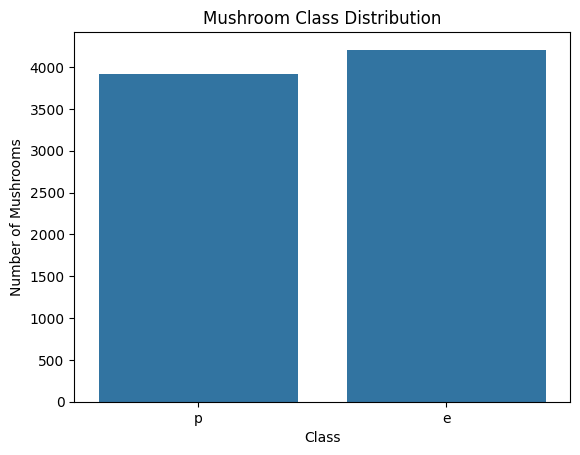

In [29]:
print(df.head())
print(df.shape)

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column information
print(df.info())

# Statistical summary
print(df.describe(include="all"))

#checking missing values
print(df.isnull().sum())
print(
    df["stalk-root"].value_counts()
)

print(df["class"].value_counts())

print(
    df["class"].value_counts(normalize=True) * 100
)

sns.countplot(data=df, x="class")

plt.title("Mushroom Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Mushrooms")

plt.show()


Defining Independent and dependent variables

split 80:20 ratio for training and testing the models.

In [30]:
# Independent variables
X = df.drop("class", axis=1)

# Dependent variable
y = df["class"]

print("Features:", X.shape)
print("Target:", y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# All 22 features are categorical
categorical_features = X.columns.tolist()

Features: (8124, 22)
Target: (8124,)
Training records: 6499
Testing records: 1625


Creating Preprocessing Transformer for all the models except for Naive Bayes.

In [31]:
# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

Preprocessor for Naive Bayes

In [32]:
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

# Declaration of Models

In [33]:
#declaring models
models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("preprocessor", nb_preprocessor),
        ("classifier", GaussianNB())
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}
trained_models = {}


Training all the models

In [34]:
for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} training completed!\n")

# Importing the Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training KNN...
KNN training completed!

Training Naive Bayes...
Naive Bayes training completed!

Training SVM...
SVM training completed!



Evaluate the Models


Logistic Regression
{'Accuracy': 1.0, 'AUC': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1 Score': 1.0, 'MCC': 1.0, 'Model': 'Logistic Regression'}

Decision Tree
{'Accuracy': 1.0, 'AUC': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1 Score': 1.0, 'MCC': 1.0, 'Model': 'Decision Tree'}

KNN
{'Accuracy': 0.9987692307692307, 'AUC': 1.0, 'Precision': 1.0, 'Recall': 0.9974457215836526, 'F1 Score': 0.9987212276214834, 'MCC': 0.997538022397975, 'Model': 'KNN'}

Naive Bayes
{'Accuracy': 0.9618461538461538, 'AUC': 0.9950787670297867, 'Precision': 0.9286563614744352, 'Recall': 0.9974457215836526, 'F1 Score': 0.9618226600985221, 'MCC': 0.926146076747352, 'Model': 'Naive Bayes'}

SVM
{'Accuracy': 0.9987692307692307, 'AUC': 1.0, 'Precision': 1.0, 'Recall': 0.9974457215836526, 'F1 Score': 0.9987212276214834, 'MCC': 0.997538022397975, 'Model': 'SVM'}

Model Comparison
                     Accuracy     AUC  Precision  Recall  F1 Score     MCC
Model                                                              

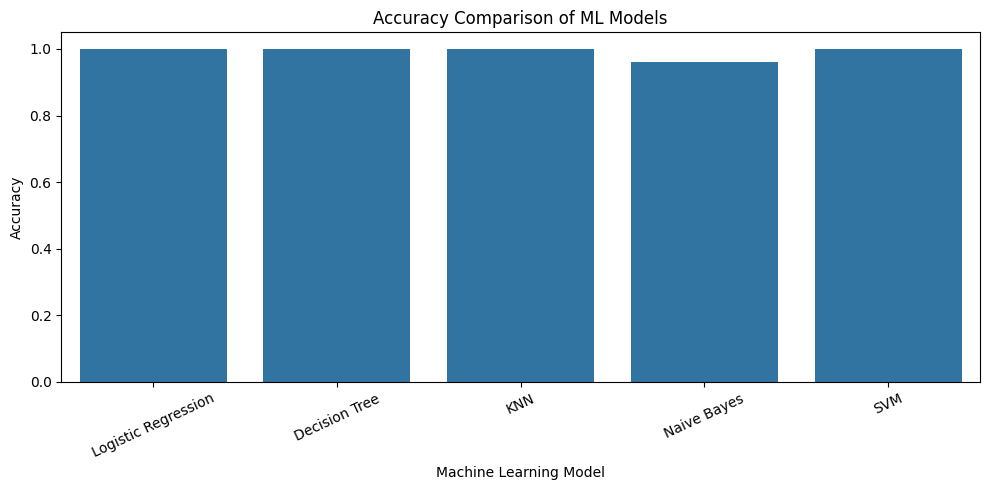

In [35]:
def evaluate_model(model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Get probability of poisonous class
    classifier = model.named_steps["classifier"]

    positive_index = list(classifier.classes_).index("p")

    y_prob = model.predict_proba(X_test)[:, positive_index]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=["e", "p"]
    )

    precision = precision_score(
        y_test,
        y_pred,
        pos_label="p",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        pos_label="p",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        pos_label="p",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    return {
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    }
    

results = []

for name, model in trained_models.items():

    metrics = evaluate_model(
        model,
        X_test,
        y_test
    )

    metrics["Model"] = name

    results.append(metrics)

    print(f"\n{name}")
    print(metrics)

results_df = pd.DataFrame(results)

results_df = results_df.set_index("Model")

print("\nModel Comparison")
print(results_df.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=results_df.index,
    y=results_df["Accuracy"]
)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


Performance comparison of models

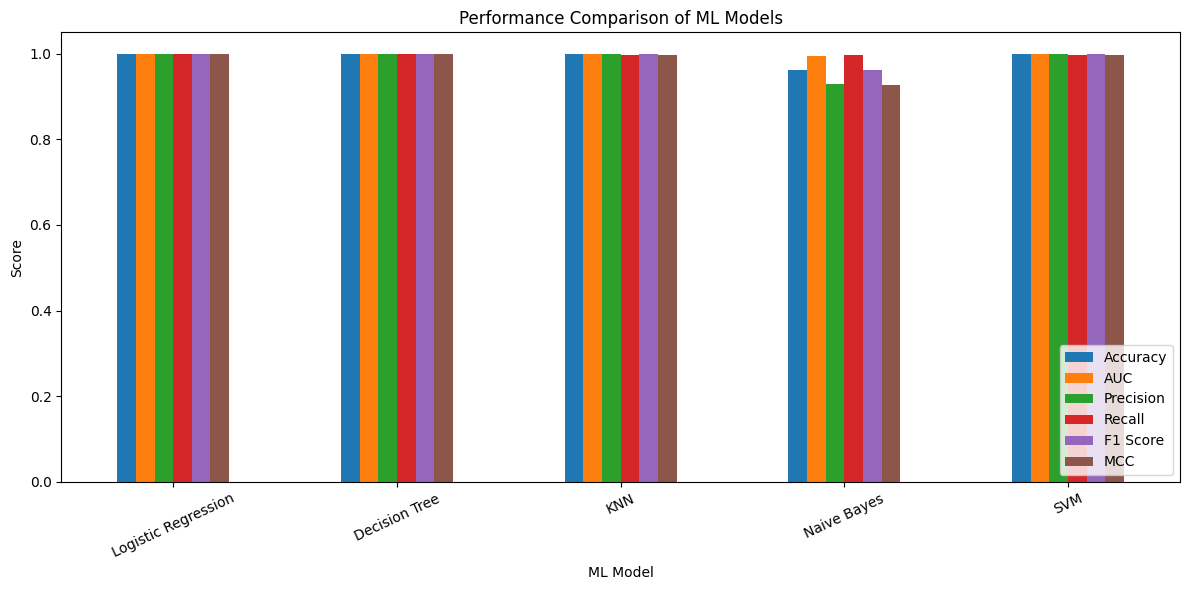

In [36]:
results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("ML Model")

plt.xticks(rotation=25)
plt.legend(loc="lower right")
plt.tight_layout()

plt.show()

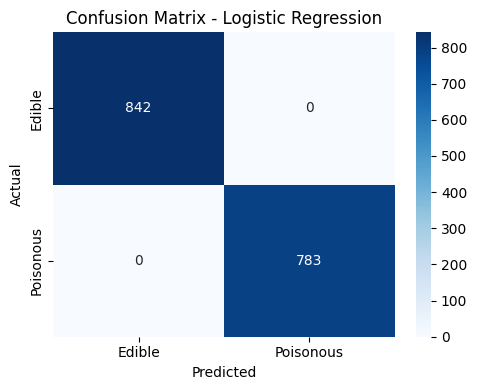

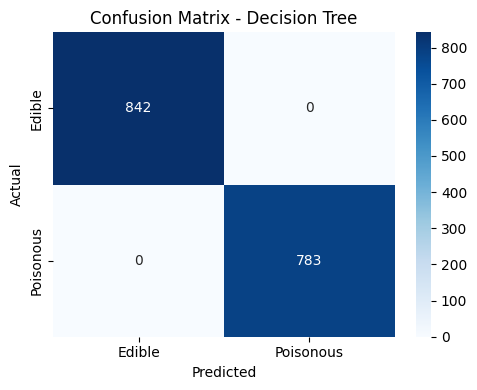

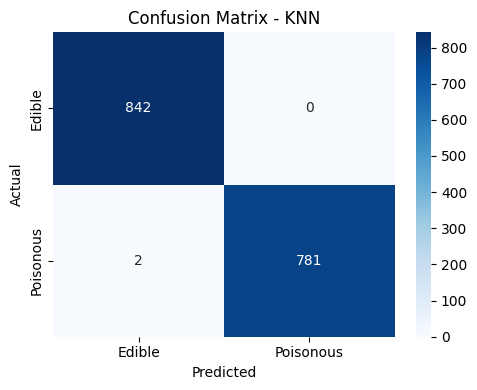

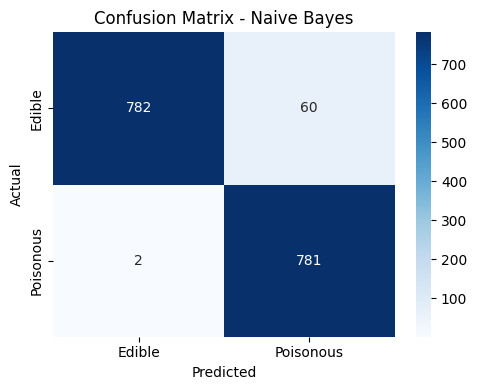

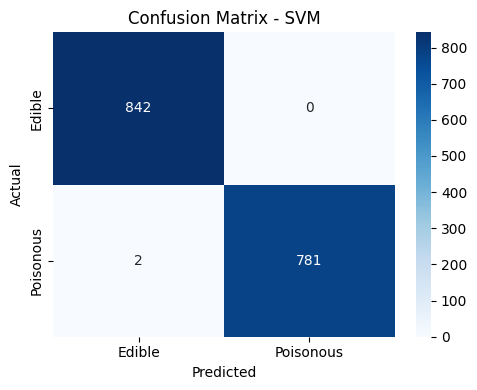


Logistic Regression
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


Decision Tree
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


KNN
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00

In [37]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["e", "p"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Edible", "Poisonous"],
        yticklabels=["Edible", "Poisonous"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()
    
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Edible", "Poisonous"]
        )
    )

best_model = results_df["MCC"].idxmax()

print("Best performing model:", best_model)

print(
    results_df.loc[best_model]
)

Save the Models for the streamlit App

In [39]:
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save all trained pipelines
for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(
        model,
        f"models/{filename}"
    )

    print(f"Saved: {filename}")

# Combine test features and actual target
test_data = X_test.copy()

test_data["class"] = y_test

# Save CSV
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")

results_df.to_csv(
    "outputs/model_comparison.csv"
)

print("Model comparison saved!")

OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib
Test dataset saved successfully!
Model comparison saved!


,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'
